# Do LLMs Know Where Alzheimer's Risk Genes Are Active?
**High_Risk_Project_Rutha · INF 385T AI in Health · Rutha Borse**


---
## Step 0 · Setup
Installs the brain-data tool **abagen** directly from its developers' GitHub page, plus the OpenAI library.

In [1]:
import os
print('PROJECT =', globals().get('PROJECT', 'NOT SET - run the save-folder cell'))
if 'PROJECT' in globals():
    print(sorted(os.listdir(PROJECT)))
print('Step 1 data loaded:', 'donor_expr' in globals())

PROJECT = NOT SET - run the save-folder cell
Step 1 data loaded: False


In [2]:
!pip install -q git+https://github.com/netneurolab/abagen.git openai

import pandas as pd, abagen, inspect, abagen.probes_ as _p
print('pandas', pd.__version__, '| abagen', abagen.__version__)
if 'inplace=False' in inspect.getsource(_p):
    print('STOP: old abagen still loaded. Runtime -> Restart session, then rerun this cell.')
elif int(pd.__version__.split('.')[0]) >= 3:
    print('STOP: pandas 3 detected. Run:  !pip install -q "pandas<3"  then Runtime -> Restart session.')
else:
    print('Setup OK - continue to the next cell.')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/abagen/mouse/io.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


pandas 2.2.3 | abagen 0.0.3+321.g1f11d61
Setup OK - continue to the next cell.


**Where files are saved.** The cell below tries Google Drive first (safest: survives disconnects).
If Drive fails, it falls back to a temporary Colab folder. In that case, run the **download cell at the end of the notebook** before you close Colab.

In [3]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive', timeout_ms=60000)
    PROJECT = '/content/drive/MyDrive/High_Risk_Project_Rutha'
except Exception as e:
    print('Drive not available (', e, ') - using a temporary folder instead.')
    PROJECT = '/content/High_Risk_Project_Rutha'
os.makedirs(PROJECT, exist_ok=True)
print('Saving to:', PROJECT)

Mounted at /content/drive
Saving to: /content/drive/MyDrive/High_Risk_Project_Rutha


---
# Part A · Build the answer key from real brain data

## Step 1 · Download gene activity for each donor brain
Six people donated their brains; scientists measured how active ~15,000 genes are in each brain region.
`return_donors=True` keeps each donor's brain **separate** and `return_counts=True` tells us how many tissue samples each region has per donor.


In [4]:
import os, glob
import numpy as np
import pandas as pd
import abagen
from abagen import matching

# Compatibility fix: abagen was written for an older numpy; this makes it work with Colab's newer numpy.
if not hasattr(np, 'row_stack'):
    np.row_stack = np.vstack
if not getattr(matching.AtlasTree._assign_sample, '_patched', False):
    _orig_assign = matching.AtlasTree._assign_sample
    def _assign_sample(self, possible, sample):
        out = _orig_assign(self, possible, sample)
        return np.asarray(out).ravel()[0] if np.ndim(out) else out
    _assign_sample._patched = True
    matching.AtlasTree._assign_sample = _assign_sample

atlas = abagen.fetch_desikan_killiany()
info = pd.read_csv(atlas['info'])

if len(glob.glob(f'{PROJECT}/expr_donor_*.csv')) == 6 and os.path.exists(f'{PROJECT}/sample_counts.csv'):
    print('Already done earlier - loading saved files (skipping the download).')
    donor_expr = {os.path.basename(f)[11:-4]: pd.read_csv(f, index_col=0)
                  for f in sorted(glob.glob(f'{PROJECT}/expr_donor_*.csv'))}
    counts = pd.read_csv(f'{PROJECT}/sample_counts.csv', index_col=0)
else:
    donor_expr, counts = abagen.get_expression_data(
        atlas['image'], atlas['info'],
        return_donors=True, return_counts=True,
        data_dir=PROJECT + '/allen_raw')
    if not isinstance(donor_expr, dict):           # older abagen returns a list
        donor_expr = dict(zip(counts.columns, donor_expr))
    for d, df in donor_expr.items():
        df.to_csv(f'{PROJECT}/expr_donor_{d}.csv')
    counts.to_csv(f'{PROJECT}/sample_counts.csv')

counts.columns = counts.columns.astype(str)
donor_expr = {str(d): df for d, df in donor_expr.items()}
for d, df in donor_expr.items():
    print(f'donor {d}: {df.shape[0]} regions x {df.shape[1]} genes')

Already done earlier - loading saved files (skipping the download).
donor 10021: 83 regions x 15633 genes
donor 12876: 83 regions x 15633 genes
donor 14380: 83 regions x 15633 genes
donor 15496: 83 regions x 15633 genes
donor 15697: 83 regions x 15633 genes
donor 9861: 83 regions x 15633 genes


## Step 2 · The Alzheimer's risk-gene list
Source: **Bellenguez et al. 2022, *Nature Genetics*** (GWAS Catalog study **GCST90027158**). Pick **one** option:

- **Option A (preferred):** download the study's associations TSV from [ebi.ac.uk/gwas/studies/GCST90027158](https://www.ebi.ac.uk/gwas/studies/GCST90027158). In Colab, click the 📁 icon on the left → upload the file → set `GWAS_FILE` below to its path (right-click the file → *Copy path*).
- **Option B:** open the [free paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9005347) and copy the gene names the authors list for each risk locus into `PASTED_GENES`.


In [6]:
import re, glob, shutil
found = glob.glob(f'{PROJECT}/gwas-association*.tsv') + glob.glob('/content/gwas-association*.tsv')
if found:
    GWAS_FILE = found[0]
else:
    from google.colab import files
    print('Choose the GWAS .tsv file from your computer:')
    up = files.upload()
    GWAS_FILE = f'{PROJECT}/' + list(up)[0]
    shutil.move('/content/' + list(up)[0], GWAS_FILE)
print('Using:', GWAS_FILE)
EXTRA_GENES = ['APOE']   # set to [] to leave out

def clean(names):
    out = set()
    for n in names:
        for g in re.split(r'[,;\s/]+', str(n)):
            g = g.strip().upper()
            if g and g not in ('NR', 'NAN', 'INTERGENIC', '-'):
                out.add(g)
    return sorted(out)

gwas = pd.read_csv(GWAS_FILE, sep='\t')
gwas['P-VALUE'] = pd.to_numeric(gwas['P-VALUE'], errors='coerce')
strong = gwas[gwas['P-VALUE'] < 5e-8]

if strong['REPORTED GENE(S)'].notna().any():
    gcol, GENE_SOURCE = 'REPORTED GENE(S)', 'reported genes (authors)'
else:
    gcol, GENE_SOURCE = 'MAPPED_GENE', 'mapped genes (GWAS Catalog)'

risk_genes = sorted(set(clean(strong[gcol].dropna())) | set(EXTRA_GENES))
strong.to_csv(f'{PROJECT}/risk_gene_sources.csv', index=False)
pd.Series(risk_genes, name='gene').to_csv(f'{PROJECT}/risk_genes.csv', index=False)

print(f'{len(strong)} associations | gene column used: {gcol} -> {GENE_SOURCE}')
print(len(risk_genes), 'risk genes:', ', '.join(risk_genes))
assert len(risk_genes) >= 20, 'Fewer than 20 genes - check Step 2 before going on.'

Choose the GWAS .tsv file from your computer:


Saving gwas-association-downloaded_2026-11-17-accessionId_GCST90027158.tsv to gwas-association-downloaded_2026-11-17-accessionId_GCST90027158.tsv
Using: /content/drive/MyDrive/High_Risk_Project_Rutha/gwas-association-downloaded_2026-11-17-accessionId_GCST90027158.tsv
87 associations | gene column used: MAPPED_GENE -> mapped genes (GWAS Catalog)
111 risk genes: ABCA1, ABCA7, ABI3, ADAM17, ADAMTS1, ANK3, ANKH, APH1B, APOE, APP, ARHGAP45, ATP8B4, BCKDK, BIN1, BLNK, CASS4, CD2AP, CLU, CR1, CR1-AS1, CTSB, CTSH, CYB561, CYYR1, DEDD, DOC2A, ECHDC3, EGFR, EPHA1-AS1, FAM157C, FENDRR, FERMT2, GPR141, GRN, HDAC2-AS2, HLA-DQA1, HLA-DRB1, HS3ST5, ICA1, IDUA, IGHG1, IGHG3, IGHV3-64, IGHV3-65, IL34, INPP5D, JAZF1, KLF16, LILRB2, LINC00917, LINC01553, LINC02059, LINC02498, LINC02695, MAF, MAF1, MINDY2-DT, MIR4280HG, MIR572, MME, MS4A4A, MYO15A, NCK2, NDUFAF6, NIFKP9, NME8, OARD1, PLCG2, PLEKHA1, PMS2P1, PPIAP55, PRKD3, PTK2B, QKILA, RASGEF1C, RBCK1, RHOH, RN7SL354P, RNA5SP431, RNU6-1307P, RNU6-560P, S

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 3 · Feasibility checkpoint
The comparison:
- **Early regions** (where Alzheimer's starts, Braak I–II): entorhinal cortex, hippocampus
- **Comparison regions** (neocortex): superior frontal, precentral, postcentral, superior parietal, lateral occipital

This cell checks how many tissue samples each donor has in each region, and how many risk genes exist in the data.

In [8]:
EARLY = ['entorhinal', 'hippocampus']
LATE  = ['superiorfrontal', 'precentral', 'postcentral', 'superiorparietal', 'lateraloccipital']
left_id = info[info['hemisphere'] == 'L'].set_index('label')['id']

region_counts = counts.loc[left_id[EARLY + LATE].values].copy()
region_counts.index = EARLY + LATE
print('Tissue samples per region (rows) and donor (columns):')
print(region_counts)
region_counts.to_csv(f'{PROJECT}/checkpoint_sample_counts.csv')

genes_in_data = set.intersection(*[set(df.columns) for df in donor_expr.values()])
found = [g for g in risk_genes if g in genes_in_data]
missing = [g for g in risk_genes if g not in genes_in_data]
print(f'\nRisk genes found in brain data: {len(found)} of {len(risk_genes)}')
print('Not found (often old gene names):', ', '.join(missing) or 'none')

ok_early = (region_counts.loc[EARLY] > 0).any(axis=0).sum()
print(f'\nDonors with samples in at least one early region: {ok_early} of {region_counts.shape[1]}')
print('CHECKPOINT:', 'GO' if ok_early >= 4 and len(found) >= 0.66 * len(risk_genes)
      else 'REVIEW - screenshot this output and ask for help')

Tissue samples per region (rows) and donor (columns):
                  9861  10021  12876  14380  15496  15697
entorhinal           4      2      2      2      2      3
hippocampus         38     26     23     24     17     18
superiorfrontal     15     16     11     12     20     18
precentral          14     10     10     10      7      7
postcentral          9      5     12     11      7     10
superiorparietal     6      9     11     12     12     11
lateraloccipital     2      8      2      6      9      9

Risk genes found in brain data: 71 of 111
Not found (often old gene names): ATP8B4, CASS4, CR1, CR1-AS1, EPHA1-AS1, FAM157C, FENDRR, GPR141, HDAC2-AS2, HLA-DQA1, IGHG1, IGHG3, IGHV3-64, IGHV3-65, LILRB2, LINC00917, LINC01553, LINC02059, LINC02498, LINC02695, MINDY2-DT, MIR4280HG, MIR572, MME, NIFKP9, NME8, PPIAP55, QKILA, RHOH, RN7SL354P, RNA5SP431, RNU6-1307P, RNU6-560P, SCIMP, SEC61G-DT, TREML2, UNC5CL, USP6NL-AS1, WDR81-AS1, ZNF594-DT

Donors with samples in at least one ea

## Step 4 · Build the answer key (donor by donor)
For each gene and each donor: **difference = average activity in early regions − average in neocortex regions.**

Labelling rule (decided **before** looking at results):
- **higher** / **lower**: at least 4 donors have data, at least 80% of them agree on the direction, and the median difference is at least 0.05
- otherwise **unclear** (left out of the scoring and reported separately)

Activity values run from 0 to 1 within each donor, so 0.05 means a 5-point shift on that scale.

In [9]:
import numpy as np
from scipy.stats import binomtest
MIN_DONORS, AGREE, MIN_EFFECT = 4, 0.80, 0.05

def donor_differences(genes):
    rows = {}
    for d, df in donor_expr.items():
        e = df.loc[df.index.intersection(left_id[EARLY].values), genes].dropna(how='all')
        l = df.loc[df.index.intersection(left_id[LATE].values), genes].dropna(how='all')
        if len(e) >= 1 and len(l) >= 3:              # usable donor
            rows[d] = e.mean() - l.mean()
    return pd.DataFrame(rows)                        # genes x donors

def make_key(diff):
    n = diff.notna().sum(axis=1)
    n_up = (diff > 0).sum(axis=1)
    agree = np.maximum(n_up, n - n_up) / n.replace(0, np.nan)
    med = diff.median(axis=1)
    label = np.where((n >= MIN_DONORS) & (agree >= AGREE) & (med.abs() >= MIN_EFFECT),
                     np.where(med > 0, 'higher', 'lower'), 'unclear')
    p = [binomtest(int(u), int(k)).pvalue if k else np.nan for u, k in zip(n_up, n)]
    return pd.DataFrame({'label': label, 'median_diff': med.round(3), 'donors': n,
                         'donors_higher': n_up, 'agreement': agree.round(2), 'sign_test_p': np.round(p, 4)})

diff_risk = donor_differences(found)
key = make_key(diff_risk)
key.insert(0, 'gene_type', 'risk')
print('Usable donors:', list(diff_risk.columns))
print(key['label'].value_counts())

Usable donors: ['10021', '12876', '14380', '15496', '15697', '9861']
label
higher     29
lower      23
unclear    19
Name: count, dtype: int64


### Positive controls
Genes whose answer should be easy, so the benchmark has clearly answerable items:
- **PROX1**, a well-known hippocampal marker
- the **5 genes with the strongest consistent differences in each direction** across all ~15,000 genes (non-risk genes only)

Controls are graded against the data exactly like risk genes.

In [10]:
all_genes = sorted(genes_in_data)
diff_all = donor_differences(all_genes)
key_all = make_key(diff_all)
pool = key_all[(key_all['label'] != 'unclear') & (~key_all.index.isin(found))]
top_up = pool[pool['label'] == 'higher'].sort_values('median_diff', ascending=False).head(5).index
top_dn = pool[pool['label'] == 'lower'].sort_values('median_diff').head(5).index
controls = list(dict.fromkeys([g for g in ['PROX1'] if g in all_genes and g not in found] + list(top_up) + list(top_dn)))

ctrl_key = key_all.loc[controls].copy()
ctrl_key.insert(0, 'gene_type', 'control')
answer_key = pd.concat([key, ctrl_key])
answer_key.index.name = 'gene'
answer_key.to_csv(f'{PROJECT}/answer_key.csv')
print(ctrl_key[['label', 'median_diff', 'agreement']])
print('\nAnswer key saved:', answer_key['label'].value_counts().to_dict())

             label  median_diff  agreement
PROX1      unclear       -0.033       0.67
PALMD       higher        0.546       1.00
C6orf118    higher        0.491       1.00
CHST9       higher        0.489       1.00
ALKAL2      higher        0.484       1.00
CPNE6       higher        0.479       1.00
MKX          lower       -0.590       1.00
THEMIS       lower       -0.572       1.00
KCNS1        lower       -0.569       1.00
LINC00507    lower       -0.551       1.00
EFNA5        lower       -0.548       1.00

Answer key saved: {'higher': 34, 'lower': 28, 'unclear': 20}


### Figure 1 · The answer key
Each dot is one donor's difference for one risk gene. Genes are sorted by median difference; colour shows the label.

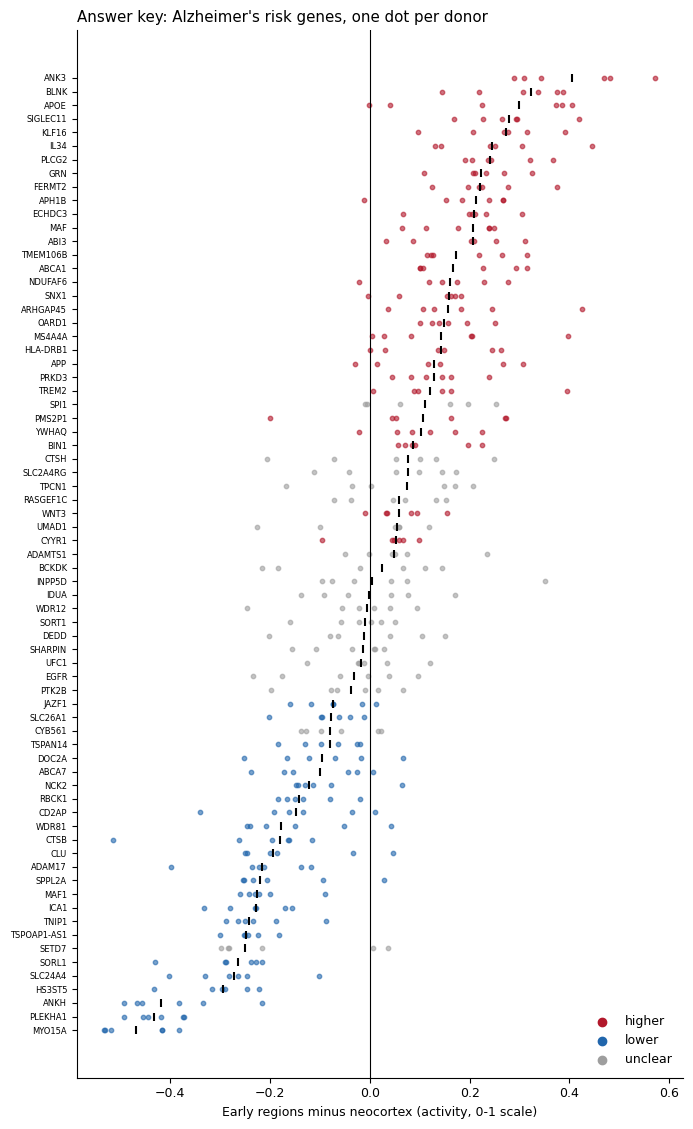

In [11]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
COL = {'higher': '#b2182b', 'lower': '#2166ac', 'unclear': '#9e9e9e'}

order = key.sort_values('median_diff').index
fig, ax = plt.subplots(figsize=(7, max(4, 0.16 * len(order))))
for i, g in enumerate(order):
    vals = diff_risk.loc[g].dropna()
    ax.scatter(vals, [i] * len(vals), s=10, color=COL[key.loc[g, 'label']], alpha=0.6)
    ax.scatter(key.loc[g, 'median_diff'], i, s=30, marker='|', color='black')
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=6)
ax.set_xlabel('Early regions minus neocortex (activity, 0-1 scale)')
ax.set_title("Answer key: Alzheimer's risk genes, one dot per donor", loc='left')
for lab, c in COL.items():
    ax.scatter([], [], color=c, label=lab)
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig(f'{PROJECT}/fig1_answer_key.png', dpi=200); plt.show()

## Step 5 · Connect to the two models through Portkey

Add **three** Colab Secrets (🔑 icon on the left → *Add new secret*, switch on *Notebook access* for each):

| Secret name | What to paste |
|---|---|
| `PORTKEY_API_KEY` | your Portkey API key |
| `PROVIDER_OPENAI` | the provider key that calls GPT-5.2 |
| `PROVIDER_ANTHROPIC` | the provider key that calls Claude Sonnet 4.5 |

A provider key may start with `@` (a slug) or not (a provider/virtual key); both work.
If the test below fails with a "model not found" error, ask your TA for the exact model names and change them in `MODEL_NAMES`.

In [12]:
from openai import OpenAI
try:
    from google.colab import userdata
    get_secret = userdata.get
except Exception:
    from getpass import getpass
    get_secret = lambda k: getpass(f'Paste {k}: ')
PORTKEY_KEY = get_secret('PORTKEY_API_KEY').strip()

MODEL_NAMES = {                                  # label -> (secret holding provider key, model name)
    'GPT-5.2':           ('PROVIDER_OPENAI',    'gpt-5.2'),
    'Claude Sonnet 4.5': ('PROVIDER_ANTHROPIC', 'claude-sonnet-4-5'),
}

def make_spec(secret, model):
    prov = get_secret(secret).strip()
    if prov.startswith('@'):                     # Model Catalog slug -> "@slug/model"
        return OpenAI(base_url='https://api.portkey.ai/v1', api_key=PORTKEY_KEY), f'{prov}/{model}'
    return (OpenAI(base_url='https://api.portkey.ai/v1', api_key=PORTKEY_KEY,
                   default_headers={'x-portkey-virtual-key': prov}), model)

SPECS = {label: make_spec(*v) for label, v in MODEL_NAMES.items()}
MODELS = list(SPECS)                             # model labels used in tables and figures
RUNS = 3                                         # same question 3 times -> consistency

def chat(label, messages):
    cl, model = SPECS[label]
    kw = {'max_tokens': 1000} if 'claude' in model.lower() else {}   # Claude requires a token limit
    r = cl.chat.completions.create(model=model, messages=messages, **kw)
    return r.choices[0].message.content or ''

for m in MODELS:                                 # connection test
    print(m, '->', chat(m, [{'role': 'user', 'content': 'Reply with the word OK.'}]).strip()[:40])

GPT-5.2 -> OK
Claude Sonnet 4.5 -> OK


## Step 6 · The prompt (fixed for every gene)
healthy adult brain, "where Alzheimer's starts" defined as Braak I–II (entorhinal cortex and hippocampus), and **"unknown" allowed**.

In [13]:
SYSTEM = ("You are a careful neuroscience expert. Answer only from your own knowledge. "
          "If you are not reasonably sure, answer \"unknown\".")
PROMPT = (
    "Consider the gene {gene} in the healthy adult human brain (no disease). "
    "Compare its mRNA expression in the regions where Alzheimer's disease pathology typically begins "
    "(the entorhinal cortex and hippocampus, Braak stages I-II) with its expression in the neocortex "
    "(frontal, parietal, central and occipital cortex).\n"
    "Is {gene} expressed higher or lower in the entorhinal cortex and hippocampus than in the neocortex?\n"
    'Reply with JSON only: {{"answer": "higher" | "lower" | "unknown", '
    '"confidence": <0-100, your probability that your answer is correct>, '
    '"reason": "<one short sentence>"}}')
print(PROMPT.format(gene='PROX1'))

Consider the gene PROX1 in the healthy adult human brain (no disease). Compare its mRNA expression in the regions where Alzheimer's disease pathology typically begins (the entorhinal cortex and hippocampus, Braak stages I-II) with its expression in the neocortex (frontal, parietal, central and occipital cortex).
Is PROX1 expressed higher or lower in the entorhinal cortex and hippocampus than in the neocortex?
Reply with JSON only: {"answer": "higher" | "lower" | "unknown", "confidence": <0-100, your probability that your answer is correct>, "reason": "<one short sentence>"}


## Step 7 · Ask the models
Every answer is written to `llm_answers.csv` as it arrives, so if Colab disconnects you can rerun this cell and it **continues where it stopped**.
About 80 genes × 2 models × 3 runs ≈ 480 calls. GPT-5.2 thinks before answering, so this can take 30–60 minutes.

In [14]:
import json, time, re
OUT = f'{PROJECT}/llm_answers.csv'
done = pd.read_csv(OUT) if os.path.exists(OUT) else pd.DataFrame(columns=['gene', 'model', 'run'])
done_keys = set(zip(done['gene'], done['model'], done['run']))
genes_to_ask = list(answer_key.index)        # unclear genes are asked too, then reported separately

def parse(text):
    m = re.search(r'\{.*\}', text, flags=re.S)           # find the JSON part of the reply
    j = json.loads(m.group(0)) if m else {}
    ans = str(j.get('answer', '')).strip().lower()
    ans = ans if ans in ('higher', 'lower', 'unknown') else 'unparsed'
    return ans, pd.to_numeric(j.get('confidence'), errors='coerce'), str(j.get('reason', ''))[:300]

def ask(label, gene):
    for attempt in range(4):
        try:
            text = chat(label, [{'role': 'system', 'content': SYSTEM},
                                {'role': 'user', 'content': PROMPT.format(gene=gene)}])
            return parse(text)
        except Exception as e:
            print('  retry', gene, label, type(e).__name__, str(e)[:120]); time.sleep(2 ** attempt)
    return 'error', np.nan, ''

todo = [(g, m, r) for m in MODELS for g in genes_to_ask for r in range(1, RUNS + 1)
        if (g, m, r) not in done_keys]
print(f'{len(todo)} calls to make ({len(done_keys)} already saved)')
for i, (g, m, r) in enumerate(todo, 1):
    ans, conf, why = ask(m, g)
    row = pd.DataFrame([{'gene': g, 'model': m, 'run': r, 'answer': ans, 'confidence': conf, 'reason': why}])
    row.to_csv(OUT, mode='a', header=not os.path.exists(OUT), index=False)
    if i % 25 == 0: print(f'  {i}/{len(todo)}')
answers = pd.read_csv(OUT)
print('Done.', answers.groupby('model')['answer'].value_counts().unstack(fill_value=0))

492 calls to make (0 already saved)
  25/492
  50/492
  75/492
  100/492
  125/492
  150/492
  175/492
  200/492
  225/492
  250/492
  275/492
  300/492
  325/492
  350/492
  375/492
  400/492
  425/492
  450/492
  475/492
Done. answer             higher  lower  unknown
model                                    
Claude Sonnet 4.5      33     15      198
GPT-5.2                13      8      225


---
# Part C · Score the LLMs

## Step 8 · The scorecard
Scored only on genes the brain data gives a clear answer for (higher or lower). Metrics:

| Metric | Plain meaning |
|---|---|
| Coverage | Share of questions answered (not "unknown") |
| Accuracy (answered) | Of the questions it answered, how many were right |
| Accuracy (all) | "Unknown" counted as not right |
| Macro-F1 | Accuracy that treats "higher" and "lower" equally |
| Confidently wrong | Share of answers that were wrong **and** had confidence ≥ 80 |
| ECE | Calibration error: gap between stated confidence and real accuracy (0 = perfect) |
| Consistency | Share of genes where all 3 runs gave the same answer |
| Baselines | Always guessing the most common label, and guessing at random |

In [15]:
from sklearn.metrics import f1_score
graded = answers.merge(answer_key[['gene_type', 'label']], left_on='gene', right_index=True)
clear = graded[graded['label'] != 'unclear'].copy()
clear['answered'] = clear['answer'].isin(['higher', 'lower'])
clear['correct'] = clear['answer'] == clear['label']

def ece(df, bins=5):
    a = df[df['answered'] & df['confidence'].notna()]
    if a.empty: return np.nan
    b = pd.cut(a['confidence'].clip(0, 100), np.linspace(0, 100, bins + 1), include_lowest=True)
    g = a.groupby(b, observed=True).agg(conf=('confidence', 'mean'), acc=('correct', 'mean'), n=('correct', 'size'))
    return float((g['n'] / g['n'].sum() * (g['conf'] / 100 - g['acc']).abs()).sum())

def boot_ci(x, n=2000, seed=0):
    x = np.asarray(x, float)
    if len(x) == 0: return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    m = rng.choice(x, (n, len(x))).mean(axis=1)
    return tuple(np.round(np.percentile(m, [2.5, 97.5]), 2))

def score(df):
    a = df[df['answered']]
    runs = df.groupby('gene')['answer'].nunique()
    return pd.Series({
        'questions': len(df),
        'coverage': round(df['answered'].mean(), 2),
        'accuracy_answered': round(a['correct'].mean(), 2) if len(a) else np.nan,
        'acc_answered_95CI': boot_ci(a['correct']),
        'accuracy_all': round(df['correct'].mean(), 2),
        'macro_F1': round(f1_score(a['label'], a['answer'], average='macro'), 2) if len(a) else np.nan,
        'confidently_wrong': round(((~a['correct']) & (a['confidence'] >= 80)).mean(), 2) if len(a) else np.nan,
        'ECE': round(ece(df), 3),
        'consistency': round((runs == 1).mean(), 2),
    })

rows = {}
for m in MODELS:
    for t in ['risk', 'control']:
        rows[(m, t)] = score(clear[(clear['model'] == m) & (clear['gene_type'] == t)])
scorecard = pd.DataFrame(rows).T

truth = answer_key.loc[answer_key['label'] != 'unclear']
for t in ['risk', 'control']:
    lab = truth[truth['gene_type'] == t]['label']
    rows_b = {'questions': len(lab), 'coverage': 1.0,
              'accuracy_answered': round(lab.value_counts(normalize=True).max(), 2),
              'accuracy_all': round(lab.value_counts(normalize=True).max(), 2)}
    scorecard.loc[('baseline: majority class', t), list(rows_b)] = list(rows_b.values())
    scorecard.loc[('baseline: random guess', t), ['questions', 'coverage', 'accuracy_answered', 'accuracy_all']] = [len(lab), 1.0, 0.5, 0.5]

scorecard.index.names = ['model', 'genes']
scorecard.to_csv(f'{PROJECT}/scorecard.csv')
print('Clear-answer genes:', truth['gene_type'].value_counts().to_dict(),
      '| unclear risk genes:', int((answer_key['label'] == 'unclear').sum()))
scorecard

Clear-answer genes: {'risk': 52, 'control': 10} | unclear risk genes: 20


questions coverage accuracy_answered  \
model                    genes                                          
GPT-5.2                  risk          156     0.04              0.29   
                         control        30      0.2              0.83   
Claude Sonnet 4.5        risk          156     0.21              0.34   
                         control        30      0.1               1.0   
baseline: majority class risk           52      1.0              0.56   
baseline: random guess   risk           52      1.0               0.5   
baseline: majority class control        10      1.0               0.5   
baseline: random guess   control        10      1.0               0.5   

                                 acc_answered_95CI accuracy_all macro_F1  \
model                    genes                                             
GPT-5.2                  risk          (0.0, 0.57)         0.01     0.22   
                         control        (0.5, 1.0)         0.17     0.83   
Claude Sonnet 4.5        risk          (0.19, 0.5)         0.07     0.33   
                         control        (1.0, 1.0)          0.1      1.0   
baseline: majority class risk                  NaN         0.56      NaN   
baseline: random guess   risk                  NaN          0.5      NaN   
baseline: majority class control               NaN          0.5      NaN   
baseline: random guess   control               NaN          0.5      NaN   

                                 confidently_wrong    ECE consistency  
model                    genes                                         
GPT-5.2                  risk                  0.0  0.331        0.92  
                         control               0.0   0.19         0.8  
Claude Sonnet 4.5        risk                  0.0  0.459        0.98  
                         control               0.0    0.5         0.8  
baseline: majority class risk                  NaN    NaN         NaN  
baseline: random guess   risk                  NaN    NaN         NaN  
baseline: majority class control               NaN    NaN         NaN  
baseline: random guess   control               NaN    NaN         NaN

### Figure 2 · Accuracy vs baselines, and confidently-wrong rate

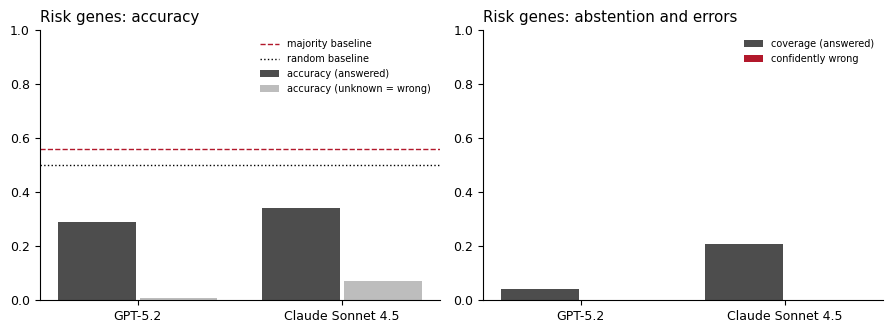

In [16]:
risk = scorecard.xs('risk', level='genes')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
x = np.arange(len(MODELS))
a1.bar(x - 0.2, risk.loc[MODELS, 'accuracy_answered'].astype(float), 0.38, color='#4d4d4d', label='accuracy (answered)')
a1.bar(x + 0.2, risk.loc[MODELS, 'accuracy_all'].astype(float), 0.38, color='#bdbdbd', label='accuracy (unknown = wrong)')
a1.axhline(float(risk.loc['baseline: majority class', 'accuracy_all']), ls='--', color='#b2182b', lw=1, label='majority baseline')
a1.axhline(0.5, ls=':', color='black', lw=1, label='random baseline')
a1.set_xticks(x); a1.set_xticklabels(MODELS); a1.set_ylim(0, 1); a1.set_title('Risk genes: accuracy', loc='left')
a1.legend(frameon=False, fontsize=7, loc='upper right')
a2.bar(x - 0.2, risk.loc[MODELS, 'coverage'].astype(float), 0.38, color='#4d4d4d', label='coverage (answered)')
a2.bar(x + 0.2, risk.loc[MODELS, 'confidently_wrong'].astype(float), 0.38, color='#b2182b', label='confidently wrong')
a2.set_xticks(x); a2.set_xticklabels(MODELS); a2.set_ylim(0, 1); a2.set_title('Risk genes: abstention and errors', loc='left')
a2.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(f'{PROJECT}/fig2_scorecard.png', dpi=200); plt.show()

### Figure 3 · Calibration (does stated confidence match real accuracy?)
Points on the diagonal = well calibrated. Points **below** it = overconfident.

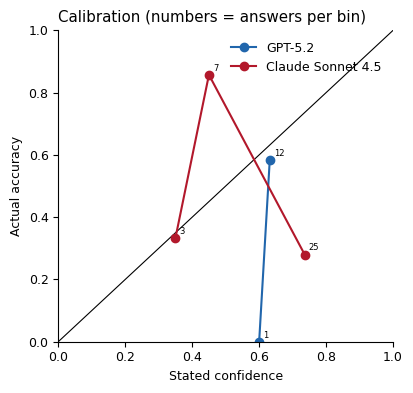

In [17]:
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], color='black', lw=0.8)
for m, c in zip(MODELS, ['#2166ac', '#b2182b', '#1b7837', '#762a83']):
    a = clear[(clear['model'] == m) & clear['answered'] & clear['confidence'].notna()]
    if a.empty: continue
    b = pd.cut(a['confidence'].clip(0, 100), np.linspace(0, 100, 6), include_lowest=True)
    g = a.groupby(b, observed=True).agg(conf=('confidence', 'mean'), acc=('correct', 'mean'), n=('correct', 'size'))
    ax.plot(g['conf'] / 100, g['acc'], marker='o', color=c, label=m)
    for _, r in g.iterrows():
        ax.annotate(int(r['n']), (r['conf'] / 100, r['acc']), fontsize=6, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Stated confidence'); ax.set_ylabel('Actual accuracy'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title('Calibration (numbers = answers per bin)', loc='left'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f'{PROJECT}/fig3_calibration.png', dpi=200); plt.show()

### Error examples for the report and slides
The confidently-wrong answers, with what the brain data actually show.

In [18]:
errs = clear[clear['answered'] & ~clear['correct'] & (clear['confidence'] >= 80)]
errs = errs.merge(answer_key[['median_diff', 'agreement']], left_on='gene', right_index=True)
errs = errs.sort_values('confidence', ascending=False)[['gene', 'gene_type', 'model', 'answer', 'label', 'confidence', 'median_diff', 'agreement', 'reason']]
errs.to_csv(f'{PROJECT}/confident_errors.csv', index=False)
print(len(errs), 'confidently wrong answers')
errs.drop_duplicates(['gene', 'model']).head(10)

0 confidently wrong answers


,gene,gene_type,model,answer,label,confidence,median_diff,agreement,reason
gene,,,,,,,,,


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/google/colab/data_table.py", line 177, in _repr_mimebundle_
    dataframe = self._preprocess_dataframe()
  File "/usr/local/lib/python3.13/dist-packages/google/colab/data_table.py", line 170, in _preprocess_dataframe
    dataframe = dataframe.reset_index()
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/frame.py", line 6472, in reset_index
    new_obj.insert(
    ~~~~~~~~~~~~~~^
        0,
        ^^
    ...<2 lines>...
        allow_duplicates=allow_duplicates,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/frame.py", line 5158, in insert
    raise ValueError(f"cannot insert {column}, already exists")
ValueError: cannot insert gene, already exists
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/google/colab/data_table.py", line 189, in _repr_javascript_module_
    return self._gen_js(self._

---
## Step 9 · Download everything
Downloads one zip with the answer key, LLM answers, scorecard and figures (not the 4 GB raw data).

In [19]:
import shutil
keep = [f for f in os.listdir(PROJECT) if f.endswith(('.csv', '.png')) and not f.startswith('expr_donor')]
os.makedirs('/content/High_Risk_Project_Rutha_results', exist_ok=True)
for f in keep: shutil.copy(f'{PROJECT}/{f}', '/content/High_Risk_Project_Rutha_results/')
shutil.make_archive('/content/High_Risk_Project_Rutha_results', 'zip', '/content/High_Risk_Project_Rutha_results')
print('Files:', sorted(keep))
try:
    from google.colab import files; files.download('/content/High_Risk_Project_Rutha_results.zip')
except Exception:
    print('Zip saved at /content/High_Risk_Project_Rutha_results.zip')

Files: ['answer_key.csv', 'checkpoint_sample_counts.csv', 'confident_errors.csv', 'fig1_answer_key.png', 'fig2_scorecard.png', 'fig3_calibration.png', 'llm_answers.csv', 'risk_gene_sources.csv', 'risk_genes.csv', 'sample_counts.csv', 'scorecard.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# ---- Experiment 2: forced answer (no "unknown" allowed) ----
import json, time, re, os
FORCED_PROMPT = PROMPT.replace('"higher" | "lower" | "unknown"', '"higher" | "lower"') + \
    '\nYou must choose "higher" or "lower" even if unsure; express uncertainty only through the confidence number.'
FORCED_SYSTEM = "You are a careful neuroscience expert. Answer only from your own knowledge."
print(FORCED_PROMPT.format(gene='SORL1'))

OUT2 = f'{PROJECT}/llm_answers_forced.csv'
done2 = pd.read_csv(OUT2) if os.path.exists(OUT2) else pd.DataFrame(columns=['gene', 'model', 'run'])
keys2 = set(zip(done2['gene'], done2['model'], done2['run']))
todo2 = [(g, m, r) for m in MODELS for g in answer_key.index for r in range(1, RUNS + 1) if (g, m, r) not in keys2]
print(len(todo2), 'calls to make')

for i, (g, m, r) in enumerate(todo2, 1):
    res = ('error', np.nan, '')
    for attempt in range(4):
        try:
            res = parse(chat(m, [{'role': 'system', 'content': FORCED_SYSTEM},
                                 {'role': 'user', 'content': FORCED_PROMPT.format(gene=g)}])); break
        except Exception as e:
            print('  retry', g, m, type(e).__name__); time.sleep(2 ** attempt)
    pd.DataFrame([{'gene': g, 'model': m, 'run': r, 'answer': res[0], 'confidence': res[1], 'reason': res[2]}]) \
      .to_csv(OUT2, mode='a', header=not os.path.exists(OUT2), index=False)
    if i % 25 == 0: print(f'  {i}/{len(todo2)}')

forced = pd.read_csv(OUT2).merge(answer_key[['gene_type', 'label']], left_on='gene', right_index=True)
fc = forced[forced['label'] != 'unclear'].copy()
fc['correct'] = fc['answer'] == fc['label']
summary = fc.groupby(['model', 'gene_type']).agg(questions=('correct', 'size'), accuracy=('correct', 'mean'),
            mean_conf=('confidence', 'mean'),
            conf_when_right=('confidence', lambda s: s[fc.loc[s.index, 'correct']].mean()),
            conf_when_wrong=('confidence', lambda s: s[~fc.loc[s.index, 'correct']].mean())).round(2)
summary.to_csv(f'{PROJECT}/scorecard_forced.csv')
print(forced.groupby('model')['answer'].value_counts().unstack(fill_value=0))
summary

Consider the gene SORL1 in the healthy adult human brain (no disease). Compare its mRNA expression in the regions where Alzheimer's disease pathology typically begins (the entorhinal cortex and hippocampus, Braak stages I-II) with its expression in the neocortex (frontal, parietal, central and occipital cortex).
Is SORL1 expressed higher or lower in the entorhinal cortex and hippocampus than in the neocortex?
Reply with JSON only: {"answer": "higher" | "lower", "confidence": <0-100, your probability that your answer is correct>, "reason": "<one short sentence>"}
You must choose "higher" or "lower" even if unsure; express uncertainty only through the confidence number.
492 calls to make
  25/492
  50/492
  75/492
  100/492
  125/492
  150/492
  175/492
  200/492
  225/492
  250/492
  275/492
  300/492
  325/492
  350/492
  375/492
  400/492
  425/492
  450/492
  475/492
answer             higher  lower
model                           
Claude Sonnet 4.5      72    174
GPT-5.2            

questions  accuracy  mean_conf  conf_when_right  \
model             gene_type                                                    
Claude Sonnet 4.5 control           30      0.60      40.97            39.11   
                  risk             156      0.46      41.39            42.39   
GPT-5.2           control           30      0.57      60.63            62.12   
                  risk             156      0.53      59.84            59.80   

                             conf_when_wrong  
model             gene_type                   
Claude Sonnet 4.5 control              43.75  
                  risk                 40.55  
GPT-5.2           control              58.69  
                  risk                 59.89

In [21]:
# ===== Interactive demo: type any gene, see the brain data vs the LLMs =====
import ipywidgets as widgets
from IPython.display import display, clear_output, Markdown
import matplotlib.pyplot as plt

if 'FORCED_PROMPT' not in globals():
    FORCED_PROMPT = PROMPT.replace('"higher" | "lower" | "unknown"', '"higher" | "lower"') + \
        '\nYou must choose "higher" or "lower" even if unsure; express uncertainty only through the confidence number.'
    FORCED_SYSTEM = "You are a careful neuroscience expert. Answer only from your own knowledge."
ALL_GENES = set.intersection(*[set(df.columns) for df in donor_expr.values()])

def brain_truth(gene):
    diff = donor_differences([gene])
    k = make_key(diff).loc[gene]
    return diff.loc[gene].dropna(), k

def check_gene(gene, ask_models=True):
    gene = gene.strip().upper()
    if gene not in ALL_GENES:
        display(Markdown(f'**{gene}** is not in the brain data. Check the spelling (use the official gene symbol, e.g. SORL1).'))
        return
    vals, k = brain_truth(gene)
    tag = 'Alzheimer\'s risk gene' if gene in found else 'not on the risk-gene list'
    display(Markdown(f'### {gene}  ({tag})\n'
        f'**Brain data:** `{k["label"]}`, median difference {k["median_diff"]:+.3f}, '
        f'{int(k["donors_higher"])} of {int(k["donors"])} donors higher in early regions'))
    fig, ax = plt.subplots(figsize=(5, 2.4))
    ax.bar(vals.index.astype(str), vals.values, color=['#b2182b' if v > 0 else '#2166ac' for v in vals.values])
    ax.axhline(0, color='black', lw=0.8)
    ax.set_ylabel('early minus neocortex'); ax.set_xlabel('donor')
    ax.set_title(f'{gene}: one bar per donor brain (red = higher where AD starts)', fontsize=9, loc='left')
    plt.tight_layout(); plt.show()
    if not ask_models:
        return
    rows = []
    for m in MODELS:
        for mode, sysm, pr in [('unknown allowed', SYSTEM, PROMPT), ('forced choice', FORCED_SYSTEM, FORCED_PROMPT)]:
            try:
                ans, conf, why = parse(chat(m, [{'role': 'system', 'content': sysm},
                                                {'role': 'user', 'content': pr.format(gene=gene)}]))
            except Exception as e:
                ans, conf, why = 'error', np.nan, str(e)[:100]
            if k['label'] == 'unclear' or ans not in ('higher', 'lower'):
                verdict = '–'
            else:
                verdict = '✅ correct' if ans == k['label'] else '❌ wrong'
            rows.append({'model': m, 'mode': mode, 'answer': ans, 'confidence': conf, 'verdict': verdict, 'reason': why})
    display(pd.DataFrame(rows).style.hide(axis='index'))

box_in = widgets.Text(value='SORL1', description='Gene:', placeholder='e.g. APOE, TREM2, PROX1')
btn = widgets.Button(description='Check', button_style='primary')
use_llm = widgets.Checkbox(value=True, description='Ask the LLMs (takes ~20 s)')
out = widgets.Output()
def on_click(_):
    with out:
        clear_output(wait=True); check_gene(box_in.value, use_llm.value)
btn.on_click(on_click); box_in.on_submit(on_click)
display(widgets.HBox([box_in, btn, use_llm]), out)

Output()

In [22]:
# ===== Export data for the brain web demo =====
import json, os
from google.colab import files
left = info[info['hemisphere'] == 'L']
genes = list(answer_key.index)
region_vals = {}
for g in genes:
    per_donor = pd.concat([df.loc[df.index.intersection(left['id']), g] for df in donor_expr.values()], axis=1)
    m = per_donor.mean(axis=1, skipna=True)
    region_vals[g] = {info.set_index('id').loc[i, 'label']: (None if pd.isna(v) else round(float(v), 4)) for i, v in m.items()}
diffs = donor_differences(genes)
def load(path):
    if not os.path.exists(path): return []
    d = pd.read_csv(path)
    d['confidence'] = pd.to_numeric(d['confidence'], errors='coerce')
    return json.loads(d[['gene', 'model', 'run', 'answer', 'confidence', 'reason']].to_json(orient='records'))
out = {
    'answer_key': json.loads(answer_key.reset_index().to_json(orient='records')),
    'region_expression': region_vals,
    'donor_differences': {g: {str(d): (None if pd.isna(v) else round(float(v), 4)) for d, v in diffs.loc[g].items()} for g in diffs.index},
    'answers_unknown_allowed': load(f'{PROJECT}/llm_answers.csv'),
    'answers_forced': load(f'{PROJECT}/llm_answers_forced.csv'),
}
with open('/content/demo_data.json', 'w') as f:
    json.dump(out, f)
print({k: len(v) for k, v in out.items()})
files.download('/content/demo_data.json')

{'answer_key': 82, 'region_expression': 82, 'donor_differences': 82, 'answers_unknown_allowed': 492, 'answers_forced': 492}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>